In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dropout, Dense, Flatten, Conv2D, MaxPool2D, BatchNormalization
# layers for data augmentation
from tensorflow.keras.layers import RandomZoom, RandomTranslation, RandomBrightness, RandomRotation

from matplotlib import pyplot as plt

import pandas as pd
import numpy as np

I0000 00:00:1793964029.330350   44110 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## loading the Sign-Language MNIST hand gestures dataset
![MNIST sign-language gestures](mnist_american_sign_language.png "MNIST sign-language gestures")

In [2]:
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

labels = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']

X_train = train.iloc[:, 1:].to_numpy().reshape(-1, 28, 28)
y_train = train.iloc[:, 0].to_numpy()
X_test = test.iloc[:, 1:].to_numpy().reshape(-1, 28, 28)
y_test = test.iloc[:, 0].to_numpy()

## shapes of train and test data

In [3]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print()
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (27455, 28, 28)
y_train: (27455,)

X_test: (7172, 28, 28)
y_test: (7172,)


## show the first 12 training hand gestures

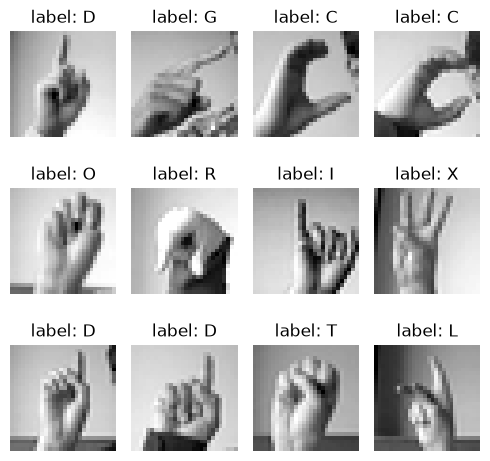

In [4]:
plt.figure(figsize=(5,5))
for k in range(12):
    subplt = plt.subplot(3, 4, k+1)
    subplt.set_title(f"label: {labels[y_train[k]]}")
    plt.imshow(X_train[k], cmap='gray')
    plt.axis('off')
plt.tight_layout()
plt.show()

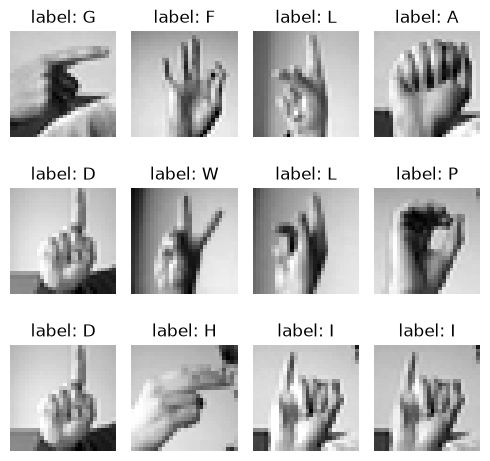

In [5]:
# show the first 12 test hand gestures

plt.figure(figsize=(5,5))
for k in range(12):
    subplt = plt.subplot(3, 4, k+1)
    subplt.set_title(f"label: {labels[y_test[k]]}")
    plt.imshow(X_test[k], cmap='gray')
    plt.axis('off')
plt.tight_layout()
plt.show()

## adjust the traning and testing input

In [6]:
X_train = X_train.reshape(-1, 28, 28, 1).astype('float32') / 255
X_test = X_test.reshape(-1, 28, 28, 1).astype('float32') / 255

from sklearn.preprocessing import LabelBinarizer
label_binarizer = LabelBinarizer()
y_train = label_binarizer.fit_transform(y_train)
y_test = label_binarizer.fit_transform(y_test)

## data augmentation and preparing for training

In [7]:
datagen = Sequential([
    RandomRotation(
        factor=10/360,
        fill_mode="nearest"
    ),
    RandomZoom(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="nearest"
    ),
    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="nearest"
    ),
    RandomBrightness(
        factor=0.1,
        value_range=(0, 1)
    ),
], name="data_augmentation")

train_dataset = (
    tf.data.Dataset
        .from_tensor_slices((X_train, y_train))
        .shuffle(1024)
        .batch(128)
        .map(
            lambda x, y: (datagen(x, training=True), y),
            num_parallel_calls=(tf.data.AUTOTUNE)
        )
)

I0000 00:00:1793964098.702674   44110 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4082 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


## building the model

In [8]:
model = Sequential()
model.add(Input(shape=(28, 28, 1)))
model.add(Conv2D(75 , (3, 3) , strides = 1 , padding = 'same' , activation = 'relu'))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2) , strides = 2 , padding = 'same'))
model.add(Conv2D(50 , (3, 3) , strides = 1 , padding = 'same' , activation = 'relu'))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2) , strides = 2 , padding = 'same'))
model.add(Conv2D(25 , (3, 3) , strides = 1 , padding = 'same' , activation = 'relu'))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2) , strides = 2 , padding = 'same'))
model.add(Flatten())
model.add(Dense(units = 512 , activation = 'relu'))
model.add(Dropout(0.3))
model.add(Dense(units = 24 , activation = 'softmax'))
model.compile(optimizer = 'adam' , loss = 'categorical_crossentropy' , metrics = ['accuracy'])

## visualization of trainable CNN

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 75)     │           750 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 75)     │           300 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 75)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 50)     │        33,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 50)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 50)     │           200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 50)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 25)       │        11,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 25)       │           100 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 25)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       205,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │        12,312 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,049 (1.01 MB)

 Trainable params: 263,749 (1.01 MB)

 Non-trainable params: 300 (1.17 KB)

/mnt/c/Users/a.zamoysky/esp32-s3_test/model/.venv/lib/python3.14/site-packages/visualkeras/layered.py:231: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


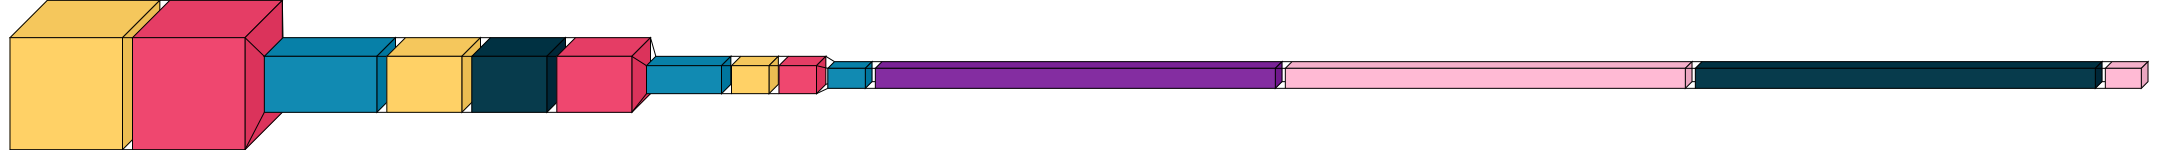

In [10]:
import visualkeras

for layer in model.layers:
    if not hasattr(layer, 'output_shape'):
        layer.output_shape = layer.output.shape
        
visualkeras.layered_view(model).show()

## training the model

In [11]:
history = model.fit(train_dataset, epochs=20, validation_data=(X_test, y_test))

Epoch 1/20


/mnt/c/Users/a.zamoysky/esp32-s3_test/model/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793964104.715401   45150 service.cc:154] XLA service 0x7f5c8051ca10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793964104.715477   45150 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce GTX 1660 SUPER, Compute Capability 7.5 (Driver: 13.3.0[610.88.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793964104.877396   45150 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793964106.435641   45253 cuda_dnn.cc:442] Loaded cuDNN version 92700


 12/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.1257 - loss: 3.2508

I0000 00:00:1793964110.585997   45150 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


215/215 ━━━━━━━━━━━━━━━━━━━━ 17s 40ms/step - accuracy: 0.6317 - loss: 1.1775 - val_accuracy: 0.1503 - val_loss: 2.9882
Epoch 2/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9175 - loss: 0.2494 - val_accuracy: 0.5864 - val_loss: 1.3961
Epoch 3/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9634 - loss: 0.1138 - val_accuracy: 0.9098 - val_loss: 0.2733
Epoch 4/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9775 - loss: 0.0714 - val_accuracy: 0.9738 - val_loss: 0.0878
Epoch 5/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9836 - loss: 0.0524 - val_accuracy: 0.9886 - val_loss: 0.0315
Epoch 6/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9859 - loss: 0.0435 - val_accuracy: 0.9522 - val_loss: 0.1325
Epoch 7/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9883 - loss: 0.0375 - val_accuracy: 0.9863 - val_loss: 0.0445
Epoch 8/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9911 - loss: 0.0276 - val_accuracy: 0.99

## analysis after model training

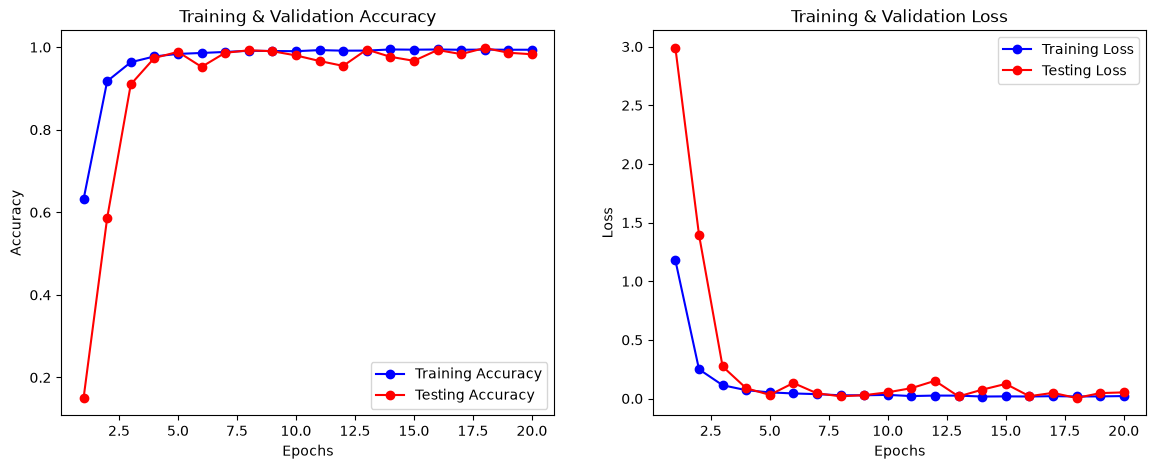

In [12]:
train_acc = history.history['accuracy']
train_loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']

epochs = range(1, len(train_loss) + 1)

fig , ax = plt.subplots(1,2)
fig.set_size_inches(14,5)

ax[0].plot(epochs , train_acc , 'bo-' , label = 'Training Accuracy')
ax[0].plot(epochs , val_acc , 'ro-' , label = 'Testing Accuracy')
ax[0].set_title('Training & Validation Accuracy')
ax[0].legend()
ax[0].set_xlabel("Epochs")
ax[0].set_ylabel("Accuracy")

ax[1].plot(epochs , train_loss , 'bo-' , label = 'Training Loss')
ax[1].plot(epochs , val_loss , 'ro-' , label = 'Testing Loss')
ax[1].set_title('Training & Validation Loss')
ax[1].legend()
ax[1].set_xlabel("Epochs")
ax[1].set_ylabel("Loss")
plt.show()

In [13]:
TFLITE_FILE = "hand_gesture_model_int8.tflite"

## converting model to tflite format

In [14]:
# choice some images from training dataset for calibration
rng = np.random.default_rng(42)
indices = rng.choice(
    len(X_train),
    size=min(300, len(X_train)),
    replace=False
)
def representative_dataset():
    for idx in indices:
        image = X_train[idx:idx+1].astype(np.float32)
        yield [image]


# creating convertor
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# optimizing model
converter.optimizations = [
    tf.lite.Optimize.DEFAULT
]

# calibration
converter.representative_dataset = representative_dataset

# integer model quantization (int8)
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8

# convertation
tflite_model = converter.convert()

# saving model as .tflite
with open(TFLITE_FILE, "wb") as f:
    f.write(tflite_model)

print("model converted successfully")
print("size KB:", len(tflite_model) / 1024)


INFO:tensorflow:Assets written to: /tmp/tmpqg3dhfwp/assets


INFO:tensorflow:Assets written to: /tmp/tmpqg3dhfwp/assets


Saved artifact at '/tmp/tmpqg3dhfwp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor_5')
Output Type:
  TensorSpec(shape=(None, 24), dtype=tf.float32, name=None)
Captures:
  140040433386272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140040433386032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140040581543360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140040581540240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140040581541200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140040581543600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140040581538080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140040581537840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140040572065008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140040572062848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1400405720652

/mnt/c/Users/a.zamoysky/esp32-s3_test/model/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793964178.840306   44110 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793964178.840348   44110 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793964178.840854   44110 reader.cc:83] Reading SavedModel from: /tmp/tmpqg3dhfwp
I0000 00:00:1793964178.841488   44110 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793964178.841494   44110 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpqg3dhfwp
I0000 00:00:1793964178.850450   44110 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1793964178.852058   44110 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793964178.896680   44110 loader.cc:221] Running init

model converted successfully
size KB: 283.90625


fully_quantize: 0, inference_type: 6, input_inference_type: UINT8, output_inference_type: UINT8
W0000 00:00:1793964179.728820   44110 flatbuffer_export.cc:4171] Skipping runtime version metadata in the model. This will be generated by the exporter.


## verification of the obtained model

In [15]:
interpreter = tf.lite.Interpreter(model_path=TFLITE_FILE)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("tf lite model input: ")
print(input_details)

print("\ntf lite model output: ")
print(output_details)

print("\noperations that the tflite micro interpreter will need: ")
for op in interpreter._get_ops_details():
    print(op["op_name"])

tf lite model input: 
[{'name': 'serving_default_keras_tensor_5:0', 'index': 0, 'shape': array([ 1, 28, 28,  1], dtype=int32), 'shape_signature': array([-1, 28, 28,  1], dtype=int32), 'dtype': <class 'numpy.uint8'>, 'quantization': (0.003921568859368563, 0), 'quantization_parameters': {'scales': array([0.00392157], dtype=float32), 'zero_points': array([0], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]

tf lite model output: 
[{'name': 'StatefulPartitionedCall_1:0', 'index': 40, 'shape': array([ 1, 24], dtype=int32), 'shape_signature': array([-1, 24], dtype=int32), 'dtype': <class 'numpy.uint8'>, 'quantization': (0.00390625, 0), 'quantization_parameters': {'scales': array([0.00390625], dtype=float32), 'zero_points': array([0], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]

operations that the tflite micro interpreter will need: 
QUANTIZE
CONV_2D
MUL
ADD
MAX_POOL_2D
CONV_2D
MUL
ADD
MAX_POOL_2D
CONV_2D
MUL
ADD

/mnt/c/Users/a.zamoysky/esp32-s3_test/model/.venv/lib/python3.14/site-packages/tensorflow/lite/python/interpreter.py:468: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## generating C array .h file of model weights for esp-tflite-micro

In [16]:
import binascii

def convert_to_c_array(bytes) -> str:
    hexstr = binascii.hexlify(bytes).decode("UTF-8")
    hexstr = hexstr.upper()
    array = ["0x" + hexstr[i:i + 2] for i in range(0, len(hexstr), 2)]
    array = [array[i:i+10] for i in range(0, len(array), 10)]
    return ",\n\t".join([", ".join(e) for e in array])

tflite_bin = open(TFLITE_FILE, 'rb').read()
c_array_bytes = convert_to_c_array(tflite_bin)

with open(TFLITE_FILE.replace(".tflite", ".h"), 'w') as f:
    f.write("\n\n")
    f.write(
        f"alignas(16) const unsigned char hand_gesture_model[] = {{\n\t{c_array_bytes}\n}};\n\n"
    )
    f.write(
        f"const int hand_gesture_model_len = {len(tflite_bin)};\n\n"
    )